# HW5 - Optimization and Genetic Algorithms

### Problem 1 & 2
hw5.pdf

### Problem 3

In [2]:
import numpy as np
from scipy.stats import rankdata
import matplotlib.pyplot as plt

In [3]:
# Parameters
population_size = 30
n_generations = 50
n_trials = 100
n_bits = 5 # 32 levels
p_crossover = 0.9
p_mutation = 0.01
p_elitism = 0.1

rng = np.random.default_rng(10)

In [4]:
x1_max = 2
x1_min = -2
x1_range = x1_max - x1_min

x2_max = 3
x2_min = -1
x2_range = x2_max - x2_min

opt_sol = np.array([1.0, 1.0])

In [5]:
def creat_population():
    gen = rng.integers(0, 2, (population_size, 2*n_bits))
    
    return gen

In [6]:
def decode(gen):
    num_list = np.arange(n_bits -1, -1, -1)
    scaling = 2 ** num_list

    d1 = gen[:, :n_bits] @ scaling
    d2 = gen[:, n_bits:] @ scaling

    x1 = x1_min + x1_range * d1 / (2**n_bits - 1)
    x2 = x2_min + x2_range * d2 / (2**n_bits - 1)

    designs = np.column_stack((x1, x2))

    return designs

In [7]:
def calculate_fitness(designs):
    x1 = designs[:, 0]
    x2 = designs[:, 1]

    scores = -((1 - x1)**2 + 100 * (x2 - x1**2)**2)

    return scores

In [8]:
def selection(gen, scores):
    # Using ranked selection
    ranks = rankdata(scores, method='average')
    prob = ranks / ranks.sum()

    idx = rng.choice(len(gen), size = len(gen), replace = True, p=prob)
    
    parents = gen[idx].copy()

    return parents

In [9]:
def crossover(parents):
    # Using single-point crossover

    children = parents.copy()

    for i in range(0, len(parents)-1, 2):

        if rng.random() < p_crossover:
            point = rng.integers(1, 2*n_bits)
            
            children[i, point:] = parents[i+1, point:]
            children[i+1, point:] = parents[i, point:]

    return children

In [10]:
def mutation(children):
    mask = rng.random(children.shape) < p_mutation

    m_children = np.bitwise_xor(children, mask.astype(int))

    return m_children

In [11]:
def run_ga():
    gen = creat_population()

    best_fitness = -np.inf
    best_solution = None

    history = []

    for iteration in range(n_generations + 1):
        # Decoding
        designs = decode(gen)

        # Fitness
        scores = calculate_fitness(designs)

        idx = np.argmax(scores)

        if scores[idx] > best_fitness:
            best_fitness = scores[idx]
            best_solution = designs[idx].copy()

        history.append(best_fitness)

        if iteration == n_generations:
            break

        # Selection
        parents = selection(gen, scores)

        # Crossover
        children = crossover(parents)

        # Mutation
        children = mutation(children)

        # Elitism
        n_elite = int(population_size * p_elitism)
                
        elite_idx = np.argsort(scores)[-n_elite:]
        elite = gen[elite_idx].copy()

        children[:n_elite] = elite

        # Update
        gen = children

    return best_solution, best_fitness, history

In [12]:
# Run 100 trials

best_solutions = []
best_fitness = []
histories = []
errors = []

for trial in range(n_trials):
    solution, score, history = run_ga()

    error = np.linalg.norm(solution - opt_sol)

    best_solutions.append(solution)
    best_fitness.append(score)
    histories.append(history)
    errors.append(error)

best_solutions = np.array(best_solutions)
best_fitness = np.array(best_fitness)
histories = np.array(histories)
errors = np.array(errors)

best_idx = np.argmax(best_fitness)

### GA Implementation
A binary GA was implemented to minimize the Rosenbrock function. Each design variable is represented by 32 levels and the population size is set to 30. Fitness is evaluated using the negative Rosenbrock function, and ranked selection is used to assign higher selection probabilities to individuals with better fitness. Single-point crossover and 1% bit flip mutation are used to generate new offspring. Elitism with a rate of 10% rate is also applied to preserve the best individuals from the current population. This process is repeated for 50 generations, and the best fitness and solutions are obtained. A total of 100 independent trials are performed to evaluate the convergence behavior, accuracy, and consistency.

In [13]:
# Results
print("Best trial:", best_idx + 1)
print("Best iteration:", np.argmax(histories[best_idx, :]))
print("Best solution:", best_solutions[best_idx])
print("Best fitness:", best_fitness[best_idx])
print("Mean fitness:", np.mean(best_fitness))

# Comparison with the true minimum
print("True minimum solution:", opt_sol)
print("Best solution error:", errors[best_idx])

Best trial: 13
Best iteration: 8
Best solution: [0.96774194 0.93548387]
Best fitness: -0.0011488639673597103
Mean fitness: -0.3146120553836889
True minimum solution: [1. 1.]
Best solution error: 0.07213122508063831


Among the 100 independent GA trials, 13th achieved the best sollution at iteration 8 (seed number = 10). The optimal solution is (0.96774194 0.93548387) with a fitness of -0.00114886, which is very close to theoretical optimum of 0. The Euclidean distance error from the true is 0.0721312; this error is due to the discretization of design variables into 32 discrete levels. Since both design variables have a range of 4, the spacing between adjacent levels is 4/31. The closest achievable values to 1 are 0.967742 (-2 + 4 * 23 / 31) for x1 and 0.935484 (-1 + 4 * 15 / 31) or 1.064516 (-1 + 4 * 16 / 31) for x2. The minimum Euclidean distance using these values is 0.07213, which matches the error obtained from the GA. Therefore, the GA successfully achieved the minimum possible error within the given discrete design space.

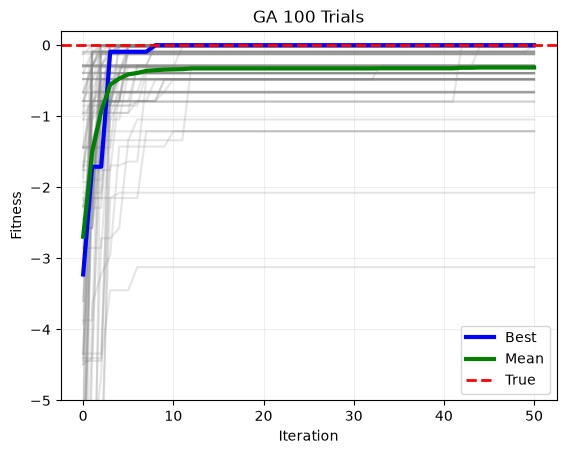

In [14]:
# Plot
mean_history = np.mean(histories, axis=0)

plt.figure()

# 100 trials
for trial in range(n_trials):

    plt.plot(histories[trial, :], color='gray', alpha=0.2)

# Best trial
plt.plot(histories[best_idx, :], color='blue', linewidth=3, label='Best')

# Mean fitness
plt.plot(mean_history, color='green', linewidth=3, label='Mean')

# True optimum
plt.axhline(0, color='red', linestyle='--', linewidth = 2, label='True')

plt.ylim(-5, 0.2)
plt.xlabel('Iteration')
plt.ylabel('Fitness')
plt.title('GA 100 Trials')

plt.legend()
plt.grid(alpha=0.2)
plt.show()

The convergence plot shows the history of 100 independent GA trials. The best trial reaches a fitness value close to the theoretical optimum of zero. The discrete binary representation and the recording of best-so-far fitness result in step-like convergence behavior. Although the best trial achieves a near-optimal fitness value, some trials stop improving before reaching the optimum. This indicates that the optimization results can depend on the initial population and the randomization of the GA.

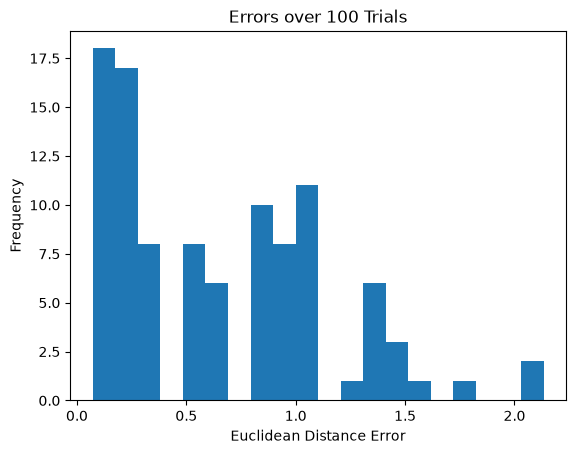

Mean error: 0.6344115532852611
Minimum error: 0.07213122508063831
Maximum error: 2.1331826603052177
Standard deviation: 0.4857797017406335


In [15]:
# Histogram
plt.figure()

plt.hist(errors, bins=20)

plt.xlabel('Euclidean Distance Error')
plt.ylabel('Frequency')
plt.title('Errors over 100 Trials')

plt.show()

print("Mean error:", np.mean(errors))
print("Minimum error:", np.min(errors))
print("Maximum error:", np.max(errors))
print("Standard deviation:", np.std(errors))

The histogram shows the distribution of Euclidean distance errors from 100 trials and the true at (1,1). Most trials achieve relatively small errors, while some produce larger errors due to the random nature of the GA and the narrow/curved valley of the Rosenbrock function. Additionally, representing each design variable with 32 discrete levels introduces unavoidable discretization error, so none of the trials achived 0 error. Overall, the GA successfully finds near-optimal solutions, but its accuracy and consistency vary acorss trials.